# Part III
**可在 Colab(GPU T4)或本機 Jupyter / VS Code 執行**,由上而下依序執行。
- 本機:結果存在 notebook 所在資料夾的 `./results`、資料快取在 `./data`(與 Part II 放同一資料夾即可共用)。
結果會存到 Google Drive 的 `MyDrive/HW3_results/`(不想掛 Drive 就設 `USE_DRIVE=False`)。

約束:不使用預訓練權重或外部資料;種子皆為 0;驗證集 = 訓練集最後 5,000 張(所有選模依據);

In [1]:
import os, sys, json, copy, random, shutil, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F

USE_DRIVE = True
SAVE_DIR, DATA_DIR = './results', './data'          # 沒掛 Drive 時存在本機(重開 Runtime 會消失)
ON_COLAB = False
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        SAVE_DIR = '/content/drive/MyDrive/HW3_results'
        DATA_DIR = '/content/drive/MyDrive/HW3_data'         # CIFAR-10 快取(與 Part II 共用,只下載一次)
        ON_COLAB = True
    except Exception as e:
        print('Not on Colab -> using local folders ./results and ./data')
os.makedirs(SAVE_DIR, exist_ok=True); os.makedirs(DATA_DIR, exist_ok=True)

def seed_all(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = False; torch.backends.cudnn.benchmark = True
seed_all(0)
dev = 'cuda' if torch.cuda.is_available() else ('mps' if getattr(torch.backends, 'mps', None) is not None and torch.backends.mps.is_available() else 'cpu')
print('device:', dev, '| SAVE_DIR:', SAVE_DIR, '| DATA_DIR:', DATA_DIR, '| torch', torch.__version__)
if dev == 'cpu': print('NOTE: no GPU found -> using the smaller CPU profile below (narrower CNN, fewer epochs).')
RESULTS = {}

if dev == 'cuda':   WIDTHS, EP_MAIN, EP_SENS = (64, 128, 256), 20, 8
elif dev == 'mps':  WIDTHS, EP_MAIN, EP_SENS = (64, 128, 256), 15, 6
else:               WIDTHS, EP_MAIN, EP_SENS = (32, 64, 128), 10, 4      # 純 CPU:網路縮小一半寬度、epoch 減少
BS, LR, WD = 256, 3e-3, 5e-2
USE_AMP = (dev == 'cuda')         # 混合精度(fp16)+ channels_last,T4 上約可加速 2 倍
warnings.filterwarnings('ignore', message='.*lr_scheduler.*')
print(f'device={dev} | WIDTHS={WIDTHS}, EP_MAIN={EP_MAIN}, EP_SENS={EP_SENS}, BS={BS}, LR={LR}, WD={WD}, AMP={USE_AMP}')

Not on Colab -> using local folders ./results and ./data
device: cuda | SAVE_DIR: ./results | DATA_DIR: ./data | torch 2.14.1+cu126
device=cuda | WIDTHS=(64, 128, 256), EP_MAIN=20, EP_SENS=8, BS=256, LR=0.003, WD=0.05, AMP=True


## 資料:CIFAR-10(只下載一次,之後直接讀 Drive 快取)
- 若 `DATA_DIR/cifar10_uint8.npz` 已存在(Part II 已建立)→ **直接讀取,不再下載**。
- 若不存在 → 用 torchvision 下載,轉成 NumPy 後**存進 Drive**(同時含 train / test)。
- 這一格只取用 `x_train`、`y_train`;**測試集要到 (d) 的測試格才讀取**。
- 前 45,000 張訓練 / 最後 5,000 張驗證(不洗牌);標準化的平均與標準差只用前 45,000 張計算。

In [2]:
CACHE = os.path.join(DATA_DIR, 'cifar10_uint8.npz')

def get_cifar10_train():
    if os.path.exists(CACHE):
        try:
            z = np.load(CACHE)                                   # npz 延遲讀取:此處只會讀 train 的兩個 key
            xt, yt = z['x_train'], z['y_train']
            assert xt.shape == (50000, 32, 32, 3) and yt.shape == (50000,)
            print('Loaded CIFAR-10 from cache:', CACHE)
            return xt, yt
        except Exception as e:
            print('Cache unreadable -> will re-download:', e)
    print('Cache not found -> downloading CIFAR-10 (one-time) ...')
    from torchvision.datasets import CIFAR10
    raw = '/content/cifar10_raw' if ON_COLAB else './cifar10_raw'
    tr = CIFAR10(raw, train=True, download=True); te = CIFAR10(raw, train=False, download=True)
    xt, yt = tr.data, np.asarray(tr.targets, dtype=np.int64)
    tmp = CACHE + '.tmp.npz'
    np.savez(tmp, x_train=xt, y_train=yt, x_test=te.data, y_test=np.asarray(te.targets, dtype=np.int64))
    os.replace(tmp, CACHE)                                       # 先寫暫存再改名,避免留下壞檔
    print('Saved cache ->', CACHE, f'({os.path.getsize(CACHE) / 1e6:.0f} MB)')
    return xt, yt

xt, yt = get_cifar10_train()
x = torch.tensor(xt).permute(0, 3, 1, 2).float() / 255.0
y = torch.tensor(yt.astype(np.int64))
mean = x[:45000].mean((0, 2, 3), keepdim=True); std = x[:45000].std((0, 2, 3), keepdim=True)
normalize = lambda t: (t - mean) / std
d = dict(xtr=normalize(x[:45000]).to(dev), ytr=y[:45000].to(dev), xva=normalize(x[45000:]).to(dev), yva=y[45000:].to(dev))
print({k: tuple(v.shape) for k, v in d.items()})
del x, xt

Loaded CIFAR-10 from cache: ./data\cifar10_uint8.npz
{'xtr': (45000, 3, 32, 32), 'ytr': (45000,), 'xva': (5000, 3, 32, 32), 'yva': (5000,)}


## 共用函式:增強、模型、層表、訓練

In [3]:
def augment(xb):
    # 隨機裁切(reflect pad 4,每張圖各自位移)+ 隨機水平翻轉,全部在 GPU 上
    n = xb.size(0)
    flip = torch.rand(n, device=xb.device) < 0.5
    xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)
    xp = F.pad(xb, (4, 4, 4, 4), mode='reflect')
    i = torch.randint(0, 9, (n,), device=xb.device); j = torch.randint(0, 9, (n,), device=xb.device)
    ar = torch.arange(32, device=xb.device)
    rows = (i[:, None] + ar)[:, None, :, None]; cols = (j[:, None] + ar)[:, None, None, :]
    return xp[torch.arange(n, device=xb.device)[:, None, None, None], torch.arange(3, device=xb.device)[None, :, None, None], rows, cols]

def basic_cnn():         # 基本 CNN: conv3x3(32)-ReLU-pool-conv3x3(64)-ReLU-pool-linear(10), padding 1
    return nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                         nn.Flatten(), nn.Linear(64 * 8 * 8, 10))

def _block(cin, cout):
    return [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]

def my_cnn(p_drop=0.3):
    L, cin = [], 3
    for cout in WIDTHS:                                       # 3 個 stage x [conv-BN-ReLU x2, pool, dropout2d]
        L += _block(cin, cout) + _block(cout, cout) + [nn.MaxPool2d(2), nn.Dropout2d(p_drop / 2)]
        cin = cout
    L += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(WIDTHS[-1], 10)]
    return nn.Sequential(*L)

def layer_table(model):
    rows, hooks = [], []
    for i, (name, m) in enumerate(model.named_children()):
        hooks.append(m.register_forward_hook(lambda m, inp, out, i=i, name=name: rows.append(
            dict(layer=f'{i}:{m.__class__.__name__}', output_shape=tuple(out.shape[1:]), params=sum(p.numel() for p in m.parameters())))))
    model.to(dev).eval()
    with torch.no_grad(): model(torch.zeros(1, 3, 32, 32, device=dev))
    for h in hooks: h.remove()
    df = pd.DataFrame(rows)
    return pd.concat([df, pd.DataFrame([dict(layer='TOTAL', output_shape='', params=int(df.params.sum()))])], ignore_index=True)

def _cl(t, fast):                 # 4D 影像張量轉成 channels_last(只在快速模式 + GPU)
    return t.contiguous(memory_format=torch.channels_last) if (fast and dev == 'cuda') else t

@torch.no_grad()
def accuracy(model, xs, ys, bs=1000, fast=True):
    model.eval(); correct = torch.zeros((), device=dev, dtype=torch.long)
    with torch.autocast('cuda', dtype=torch.float16, enabled=(fast and USE_AMP)):
        for i in range(0, len(xs), bs):
            correct += (model(_cl(xs[i:i + bs], fast)).argmax(1) == ys[i:i + bs]).sum()
    return correct.item() / len(xs)

def make_scaler(enabled):
    try: return torch.amp.GradScaler('cuda', enabled=enabled)
    except Exception: return torch.cuda.amp.GradScaler(enabled=enabled)

def fit(model, epochs, bs, lr, aug, wd=0.0, onecycle=False, verbose=True, fast=True):
    # 回傳 (history, (best_val_acc, best_state_dict));checkpoint 只依驗證集選擇
    use_amp = fast and USE_AMP
    model.to(dev)
    if fast and dev == 'cuda': model.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd) if wd else torch.optim.Adam(model.parameters(), lr=lr)
    n = len(d['xtr']); steps = epochs * ((n + bs - 1) // bs)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps) if onecycle else None
    scaler = make_scaler(use_amp)
    g = torch.Generator().manual_seed(0)
    hist = dict(loss=[], train_acc=[], val_acc=[]); best = (0.0, None)
    for ep in range(epochs):
        t0 = time.time(); model.train(); perm = torch.randperm(n, generator=g).to(dev); tot = torch.zeros((), device=dev)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]; xb, yb = d['xtr'][idx], d['ytr'][idx]
            if aug: xb = augment(xb)
            xb = _cl(xb, fast)
            with torch.autocast('cuda', dtype=torch.float16, enabled=use_amp):
                loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sch: sch.step()
            tot += loss.detach() * len(idx)
        hist['loss'].append(tot.item() / n)
        hist['train_acc'].append(accuracy(model, d['xtr'][:5000], d['ytr'][:5000], fast=fast))
        hist['val_acc'].append(accuracy(model, d['xva'], d['yva'], fast=fast))
        if hist['val_acc'][-1] > best[0]:
            best = (hist['val_acc'][-1], {k: v.detach().clone() for k, v in model.state_dict().items()})
        if verbose: print(f"ep {ep+1:2d}  loss {hist['loss'][-1]:.4f}  train {hist['train_acc'][-1]:.4f}  val {hist['val_acc'][-1]:.4f}  ({time.time() - t0:.1f}s)")
    return hist, best

def plot_curves(h, title, fname=None):
    ep = range(1, len(h['loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(ep, h['loss'], marker='o'); ax[0].set(title=f'{title}: training loss', xlabel='epoch')
    ax[1].plot(ep, h['train_acc'], marker='o', label='train (first 5k)'); ax[1].plot(ep, h['val_acc'], marker='o', label='validation')
    ax[1].set(title=f'{title}: accuracy', xlabel='epoch'); ax[1].legend(); plt.tight_layout()
    if fname: plt.savefig(os.path.join(SAVE_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()

## (a) From Pixels to Filters
六個 $5\times5\times3$ filter、stride 1、無 padding,輸入 $32\times32\times3$。

In [4]:
out_hw = (32 - 5) // 1 + 1
n_out = out_hw * out_hw * 6
conv_params = 6 * (5 * 5 * 3 + 1)
fc_params = (32 * 32 * 3) * n_out + n_out
print(f'output = {out_hw} x {out_hw} x 6 = {n_out:,}')
print(f'conv params = 6 x (5*5*3 + 1) = {conv_params}')
print(f'fully-connected layer with the same output size: {fc_params:,} params  ({fc_params / conv_params:,.0f}x more)')
# 驗證:用 PyTorch 實際建一層
t = nn.Conv2d(3, 6, 5); print('PyTorch check:', tuple(t(torch.zeros(1, 3, 32, 32)).shape), sum(p.numel() for p in t.parameters()))

output = 28 x 28 x 6 = 4,704
conv params = 6 x (5*5*3 + 1) = 456
fully-connected layer with the same output size: 14,455,392 params  (31,700x more)
PyTorch check: (1, 6, 28, 28) 456


## (b) CNN

ep  1  loss 1.3091  train 0.6542  val 0.6398  (6.1s)
ep  2  loss 0.9761  train 0.7236  val 0.6798  (1.7s)
ep  3  loss 0.8375  train 0.7410  val 0.6954  (2.3s)
ep  4  loss 0.7551  train 0.7904  val 0.7212  (2.2s)
ep  5  loss 0.6916  train 0.7940  val 0.7206  (2.1s)
ep  6  loss 0.6367  train 0.8072  val 0.7066  (1.8s)
ep  7  loss 0.5939  train 0.8352  val 0.7250  (2.0s)
ep  8  loss 0.5519  train 0.8436  val 0.7172  (2.1s)
ep  9  loss 0.5137  train 0.8606  val 0.7278  (2.2s)
ep 10  loss 0.4847  train 0.8640  val 0.7166  (1.9s)
basic CNN (conv32-conv64, Adam 1e-3, bs 64, 10 epochs): val acc = 0.7166


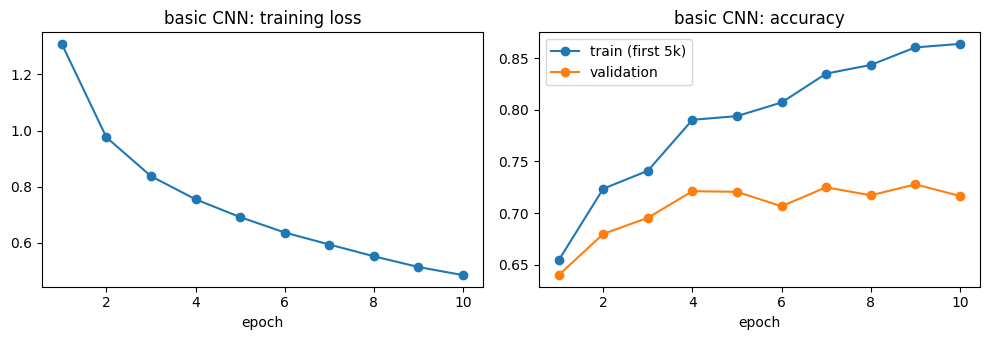

In [5]:
seed_all(0)
basic = basic_cnn()
hb, _ = fit(basic, epochs=10, bs=64, lr=1e-3, aug=False, fast=False)
print(f"basic CNN (conv32-conv64, Adam 1e-3, bs 64, 10 epochs): val acc = {hb['val_acc'][-1]:.4f}")
plot_curves(hb, 'basic CNN', 'iii_basic_cnn_curves.png')
RESULTS['basic_cnn_val_acc'] = hb['val_acc'][-1]

,layer,output_shape,params
0,0:Conv2d,"(64, 32, 32)",1728
1,1:BatchNorm2d,"(64, 32, 32)",128
2,2:ReLU,"(64, 32, 32)",0
3,3:Conv2d,"(64, 32, 32)",36864
4,4:BatchNorm2d,"(64, 32, 32)",128
5,5:ReLU,"(64, 32, 32)",0
6,6:MaxPool2d,"(64, 16, 16)",0
7,7:Dropout2d,"(64, 16, 16)",0
8,8:Conv2d,"(128, 16, 16)",73728
9,9:BatchNorm2d,"(128, 16, 16)",256


ep  1  loss 1.6773  train 0.4782  val 0.4822  (60.5s)
ep  2  loss 1.2971  train 0.4544  val 0.4646  (45.1s)
ep  3  loss 1.1142  train 0.6762  val 0.6668  (45.3s)
ep  4  loss 0.9786  train 0.6936  val 0.6934  (45.3s)
ep  5  loss 0.8569  train 0.7040  val 0.7016  (45.4s)
ep  6  loss 0.7500  train 0.7938  val 0.7818  (45.4s)
ep  7  loss 0.6715  train 0.8008  val 0.7928  (45.5s)
ep  8  loss 0.6045  train 0.8300  val 0.8136  (45.5s)
ep  9  loss 0.5583  train 0.8446  val 0.8238  (45.6s)
ep 10  loss 0.5096  train 0.8762  val 0.8448  (45.6s)
ep 11  loss 0.4691  train 0.8728  val 0.8472  (45.7s)
ep 12  loss 0.4339  train 0.9016  val 0.8672  (45.7s)
ep 13  loss 0.3966  train 0.9226  val 0.8780  (46.4s)
ep 14  loss 0.3599  train 0.9260  val 0.8848  (47.0s)
ep 15  loss 0.3263  train 0.9222  val 0.8806  (47.2s)
ep 16  loss 0.2967  train 0.9456  val 0.8990  (47.2s)
ep 17  loss 0.2710  train 0.9466  val 0.9022  (47.8s)
ep 18  loss 0.2506  train 0.9546  val 0.9044  (47.8s)
ep 19  loss 0.2371  train 0.

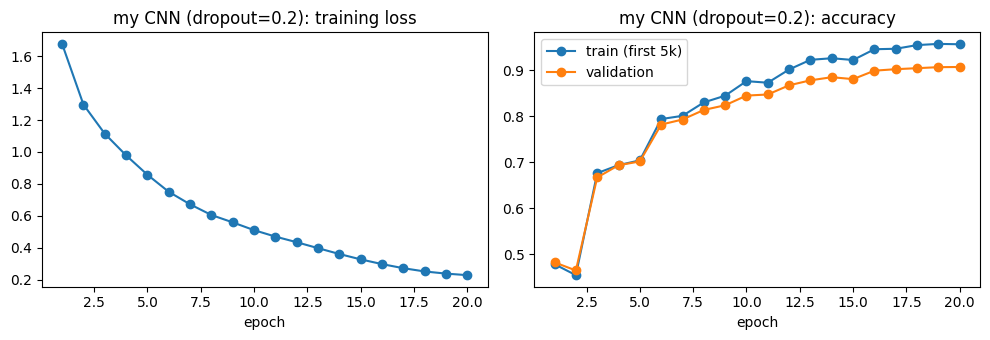

In [6]:
P_DEFAULT = 0.2
seed_all(0)
mine = my_cnn(P_DEFAULT); tbl = layer_table(mine); display(tbl)
tbl.to_csv(os.path.join(SAVE_DIR, 'iii_my_cnn_layers.csv'), index=False)
h_mine, best_mine = fit(mine, epochs=EP_MAIN, bs=BS, lr=LR, aug=True, wd=WD, onecycle=True)
print(f"my CNN (p={P_DEFAULT}): best val acc = {best_mine[0]:.4f}")
plot_curves(h_mine, f'my CNN (dropout={P_DEFAULT})', 'iii_my_cnn_curves.png')
RESULTS['my_cnn_default'] = dict(p=P_DEFAULT, best_val=best_mine[0], params=int(tbl.params.iloc[-1]))
trained = {P_DEFAULT: (h_mine, best_mine)}

## (c) Sensitivity Study
其餘設定固定(每組 `EP_SENS` 個 epoch(GPU 8、CPU 4),與 (b) 相同的增強、batch、排程;為節省時間比最終模型短)。記錄最佳 epoch 驗證準確率、最後 epoch 的訓練/驗證準確率。
每組結果會存進 Drive(`iii_sens_cache.json`),Colab 中途斷線後重跑會自動跳過已完成的組;**若改了 EP_SENS/BS/LR/WD,快取的 key 會不同,自動重跑**。

(cached) {'dropout': 0.0, 'train_acc_last': 0.9226, 'val_acc_last': 0.8804, 'val_acc_best': 0.8804, 'gap': 0.042200000000000015}
(cached) {'dropout': 0.2, 'train_acc_last': 0.8828, 'val_acc_last': 0.8584, 'val_acc_best': 0.8584, 'gap': 0.024399999999999977}
(cached) {'dropout': 0.4, 'train_acc_last': 0.8408, 'val_acc_last': 0.8226, 'val_acc_best': 0.8226, 'gap': 0.018199999999999994}
(cached) {'dropout': 0.6, 'train_acc_last': 0.7654, 'val_acc_last': 0.753, 'val_acc_best': 0.753, 'gap': 0.012399999999999967}


,dropout,train_acc_last,val_acc_last,val_acc_best,gap
0,0.000000,0.9226,0.8804,0.8804,0.0422
1,0.200000,0.8828,0.8584,0.8584,0.0244
2,0.400000,0.8408,0.8226,0.8226,0.0182
3,0.600000,0.7654,0.7530,0.7530,0.0124


best dropout (by validation accuracy): 0.0


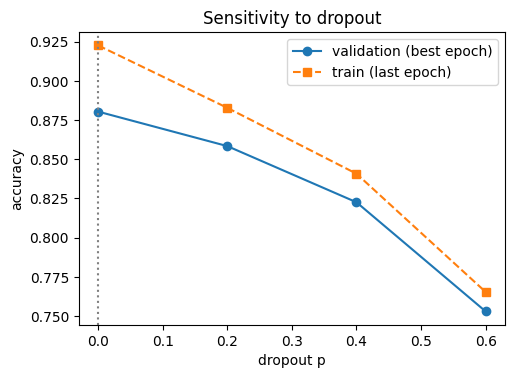

In [7]:
SENS_FILE = os.path.join(SAVE_DIR, 'iii_sens_cache.json')
sens_cache = json.load(open(SENS_FILE)) if os.path.exists(SENS_FILE) else {}
sens = []
for p in [0.0, 0.2, 0.4, 0.6]:
    key = f'p{p}_ep{EP_SENS}_bs{BS}_lr{LR}_wd{WD}'
    if key in sens_cache:
        row = sens_cache[key]; print('(cached)', row)
    else:
        seed_all(0)
        m = my_cnn(p); h, b = fit(m, epochs=EP_SENS, bs=BS, lr=LR, aug=True, wd=WD, onecycle=True, verbose=False)
        row = dict(dropout=p, train_acc_last=h['train_acc'][-1], val_acc_last=h['val_acc'][-1], val_acc_best=b[0], gap=h['train_acc'][-1] - h['val_acc'][-1])
        sens_cache[key] = row; json.dump(sens_cache, open(SENS_FILE, 'w'))      # 每組做完立刻存檔
        print(row)
    sens.append(row)
sdf = pd.DataFrame(sens); display(sdf.style.format({c: '{:.4f}' for c in sdf.columns if c != 'dropout'}))
BEST_P = float(sdf.loc[sdf.val_acc_best.idxmax(), 'dropout'])
print('best dropout (by validation accuracy):', BEST_P)
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(sdf.dropout, sdf.val_acc_best, 'o-', label='validation (best epoch)'); ax.plot(sdf.dropout, sdf.train_acc_last, 's--', label='train (last epoch)')
ax.axvline(BEST_P, color='gray', ls=':'); ax.set(xlabel='dropout p', ylabel='accuracy', title='Sensitivity to dropout'); ax.legend()
plt.savefig(os.path.join(SAVE_DIR, 'iii_sensitivity.png'), dpi=150, bbox_inches='tight'); plt.show()
RESULTS['sensitivity'] = sens; RESULTS['best_p'] = BEST_P

## (d) Final Evaluation
以驗證集選出的最佳 dropout 訓練最終模型,checkpoint 依驗證集挑選。

ep  1  loss 1.4524  train 0.5306  val 0.5268  (47.7s)
ep  2  loss 1.0675  train 0.6522  val 0.6484  (47.4s)
ep  3  loss 0.8863  train 0.5848  val 0.5754  (47.2s)
ep  4  loss 0.7538  train 0.5366  val 0.5322  (47.0s)
ep  5  loss 0.6585  train 0.7442  val 0.7460  (47.2s)
ep  6  loss 0.5719  train 0.6556  val 0.6628  (47.2s)
ep  7  loss 0.5053  train 0.7682  val 0.7628  (47.4s)
ep  8  loss 0.4477  train 0.8378  val 0.8136  (47.7s)
ep  9  loss 0.4105  train 0.7900  val 0.7692  (47.3s)
ep 10  loss 0.3706  train 0.8790  val 0.8430  (47.2s)
ep 11  loss 0.3342  train 0.8750  val 0.8464  (47.2s)
ep 12  loss 0.3019  train 0.8654  val 0.8276  (47.3s)
ep 13  loss 0.2693  train 0.9226  val 0.8788  (47.4s)
ep 14  loss 0.2301  train 0.9322  val 0.8848  (47.4s)
ep 15  loss 0.1970  train 0.9402  val 0.8886  (47.1s)
ep 16  loss 0.1685  train 0.9620  val 0.9032  (47.0s)
ep 17  loss 0.1429  train 0.9670  val 0.9022  (46.7s)
ep 18  loss 0.1196  train 0.9770  val 0.9082  (47.0s)
ep 19  loss 0.1087  train 0.

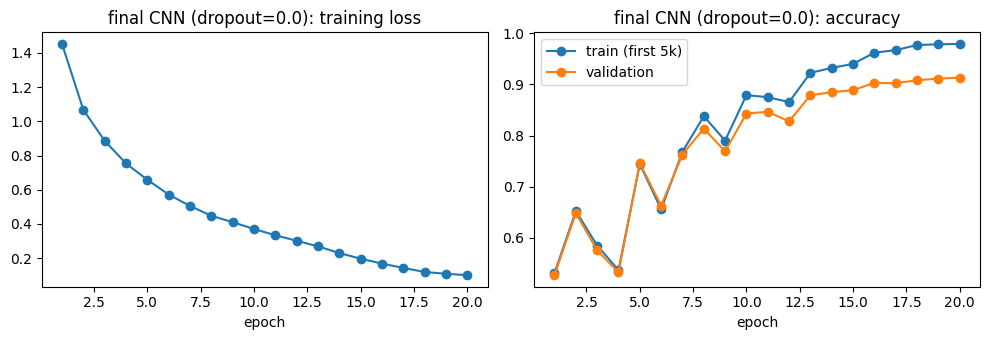

In [8]:
seed_all(0)
if BEST_P in trained:
    h_final, (vbest, best_state) = trained[BEST_P]
    final = my_cnn(BEST_P).to(dev); final.load_state_dict(best_state)
else:
    final = my_cnn(BEST_P); h_final, (vbest, st) = fit(final, epochs=EP_MAIN, bs=BS, lr=LR, aug=True, wd=WD, onecycle=True)
    final.load_state_dict(st)
if dev == 'cuda': final.to(memory_format=torch.channels_last)
print(f'final model: dropout={BEST_P}, best validation accuracy = {vbest:.4f}')
plot_curves(h_final, f'final CNN (dropout={BEST_P})', 'iii_final_curves.png')
torch.save(final.state_dict(), os.path.join(SAVE_DIR, 'final_cnn.pt'))

In [9]:
# ===== 測試集:只執行這一格一次 =====
if '_test_done' in globals():
    raise RuntimeError('The test set has already been evaluated once. Do not evaluate again.')
zt = np.load(CACHE)                                       # 此時才讀取測試集(來自同一份快取)
xte = normalize(torch.tensor(zt['x_test']).permute(0, 3, 1, 2).float() / 255.0).to(dev); yte = torch.tensor(zt['y_test'].astype(np.int64)).to(dev)
test_acc = accuracy(final, xte, yte); _test_done = True
print(f'TEST accuracy (evaluated once) = {test_acc:.4f}   | best validation accuracy = {vbest:.4f}')
RESULTS['final'] = dict(p=BEST_P, val_acc=vbest, test_acc=test_acc)

TEST accuracy (evaluated once) = 0.9110   | best validation accuracy = 0.9132


### 與 Part II 比較

In [10]:
p2 = os.path.join(SAVE_DIR, 'part2_results.json')
p2_val = json.load(open(p2))['best_model_val_acc_final'] if os.path.exists(p2) else None
cmp = pd.DataFrame([
    dict(model='My NumPy MLP (Part II)', val_acc=p2_val if p2_val is not None else np.nan, test_acc=np.nan),
    dict(model='My CNN (Part III)', val_acc=vbest, test_acc=test_acc)])
display(cmp.style.format({'val_acc': '{:.4f}', 'test_acc': '{:.4f}'}, na_rep='—'))

se = lambda p, n: (p * (1 - p) / n) ** 0.5
print(f'\nvalidation: n=5000 -> standard error ≈ {se(vbest, 5000):.4f} (95% CI ± {1.96 * se(vbest, 5000):.4f})')
print(f'test:       n=10000 -> standard error ≈ {se(test_acc, 10000):.4f} (95% CI ± {1.96 * se(test_acc, 10000):.4f})')
RESULTS['compare'] = cmp.fillna(-1).to_dict('records')
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
json.dump(_clean(RESULTS), open(os.path.join(SAVE_DIR, 'part3_results.json'), 'w'), indent=1)
print('saved:', sorted(os.listdir(SAVE_DIR)))

,model,val_acc,test_acc
0,My NumPy MLP (Part II),—,—
1,My CNN (Part III),0.9132,0.9110



validation: n=5000 -> standard error ≈ 0.0040 (95% CI ± 0.0078)
test:       n=10000 -> standard error ≈ 0.0028 (95% CI ± 0.0056)
saved: ['final_cnn.pt', 'ii_best_curves.png', 'ii_config_table.csv', 'ii_grad_flow.png', 'ii_overfit50.png', 'iii_basic_cnn_curves.png', 'iii_final_curves.png', 'iii_my_cnn_curves.png', 'iii_my_cnn_layers.csv', 'iii_sens_cache.json', 'iii_sensitivity.png', 'part3_results.json', 'submission_CNN.csv']


In [11]:
from a3_submission import export_submission
final.eval()
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
    pred = torch.cat([final(_cl(d['xva'][i:i + 1000], True)).argmax(1) for i in range(0, 5000, 1000)]).cpu().numpy().astype(np.int64)
ids = np.arange(45000, 50000)
path = export_submission(pred, ids, os.path.join(SAVE_DIR, 'submission_CNN.csv'))
shutil.copy(path, 'submission_CNN.csv')
chk = pd.read_csv('submission_CNN.csv')
assert list(chk.columns) == ['id', 'label'] and len(chk) == 5000 and chk.label.between(0, 9).all()
print('saved:', path, '| rows:', len(chk), '| label counts:', np.bincount(chk.label, minlength=10))
try:
    from google.colab import files; files.download('submission_CNN.csv')
except Exception: pass

saved: results\submission_CNN.csv | rows: 5000 | label counts: [517 483 461 526 460 532 495 480 530 516]
